# 1. The Idea
This model predicts whether a mushroom is edible or poisonous from its physical
features such as cap shape, odor, gill size and habitat.

Why it's useful: eating the wrong wild mushroom can be fatal. A model that
classifies mushrooms from observable features shows how ML can support
safety decisions, e.g. in foraging apps or food safety checks.

# 2. Data Preparation


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report


In [9]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

cols = ["class", "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
        "gill-attachment", "gill-spacing", "gill-size", "gill-color",
        "stalk-shape", "stalk-root", "stalk-surface-above-ring",
        "stalk-surface-below-ring", "stalk-color-above-ring",
        "stalk-color-below-ring", "veil-type", "veil-color", "ring-number",
        "ring-type", "spore-print-color", "population", "habitat"]

df = pd.read_csv(url, header=None, names=cols)
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [10]:
print("Shape:", df.shape)
print("\nNull values:", df.isnull().sum().sum())
print("\n'?' values per column:")
print((df == '?').sum()[lambda s: s > 0])
print("\nClass balance:\n", df['class'].value_counts())

Shape: (8124, 23)

Null values: 0

'?' values per column:
stalk-root    2480
dtype: int64

Class balance:
 class
e    4208
p    3916
Name: count, dtype: int64


We treat '?' in stalk-root as its own category ("unknown") rather than dropping
about 2,480 rows. All features are text, so we encode them as numbers.


In [11]:
# Target: e = 0 (edible), p = 1 (poisonous)
y = LabelEncoder().fit_transform(df['class'])

# Features: text categories -> numbers
X_raw = df.drop(columns='class')
X = pd.DataFrame(OrdinalEncoder().fit_transform(X_raw), columns=X_raw.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (6499, 22) | Test: (1625, 22)


# 3. Model Building: Decision Tree and KNN

In [12]:
# Model 1: Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

# Model 2: KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("Both models trained.")

Both models trained.


# 4. Evaluation


Decision Tree accuracy: 1.0000
KNN accuracy:           0.9982


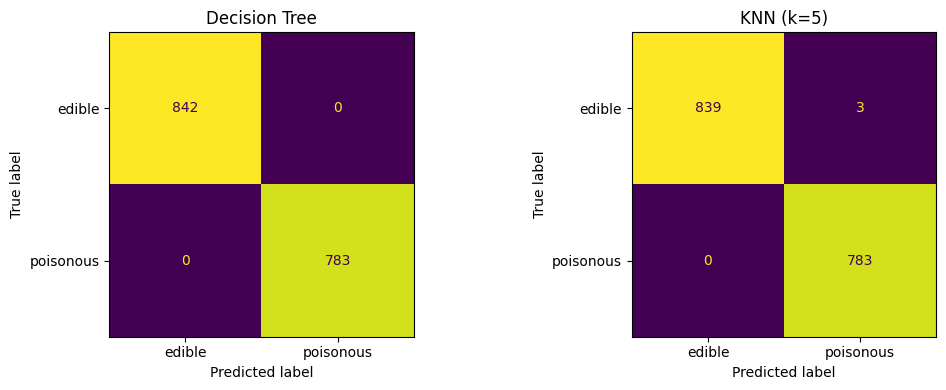

Decision Tree:
               precision    recall  f1-score   support

      edible       1.00      1.00      1.00       842
   poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625

KNN:
               precision    recall  f1-score   support

      edible       1.00      1.00      1.00       842
   poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [13]:
dt_acc = accuracy_score(y_test, dt_pred)
knn_acc = accuracy_score(y_test, knn_pred)
print(f"Decision Tree accuracy: {dt_acc:.4f}")
print(f"KNN accuracy:           {knn_acc:.4f}")

labels = ["edible", "poisonous"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in zip(axes, [dt_pred, knn_pred], ["Decision Tree", "KNN (k=5)"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=labels).plot(ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

print("Decision Tree:\n", classification_report(y_test, dt_pred, target_names=labels))
print("KNN:\n", classification_report(y_test, knn_pred, target_names=labels))

In [14]:
imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(5)
print(imp)

gill-color           0.338633
spore-print-color    0.216180
population           0.177561
gill-size            0.109882
odor                 0.035568
dtype: float64


# 5. Conclusion

- Decision Tree accuracy: 1.0000 (100%) | KNN accuracy: 0.9982 (99.82%)
- Better model: Decision Tree. It classified all 1625 test mushrooms correctly,
  while KNN made 3 mistakes.
- The 3 KNN mistakes were edible mushrooms predicted as poisonous, which is the
  safe kind of error. Neither model predicted a poisonous mushroom as edible
  (0 dangerous errors), which matters most for this problem.
- Mushroom features are very informative,
  so even simple models reach near-perfect accuracy. Real-world data is rarely
  this clean.

What I learned:
- Text categories must be encoded as numbers before training.
- Missing values can hide as '?' instead of NaN (stalk-root had 2480).
- Accuracy alone doesn't show the full picture; the confusion matrix shows
  which type of mistake a model makes, and that matters when one mistake
  (poisonous predicted as edible) is far worse than the other.